<a href="https://colab.research.google.com/github/4smaa13/predictive-maintenance-cmapss/blob/main/01_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cols = ['unit', 'cycle', 'set1', 'set2', 'set3'] + [f's{i}' for i in range(1, 22)]

train = pd.read_csv('train_FD001.txt', sep=r'\s+', header=None, names=cols)
test = pd.read_csv('test_FD001.txt', sep=r'\s+', header=None, names=cols)
rul_true = pd.read_csv('RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL'])

print(train.shape, test.shape, rul_true.shape)
train.head()

(20631, 26) (13096, 26) (100, 1)


,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
max_cycle = train.groupby('unit')['cycle'].max()
train['RUL'] = train['unit'].map(max_cycle) - train['cycle']
train['RUL'] = train['RUL'].clip(upper=125)

train[['unit', 'cycle', 'RUL']].head()


,unit,cycle,RUL
0,1,1,125
1,1,2,125
2,1,3,125
3,1,4,125
4,1,5,125


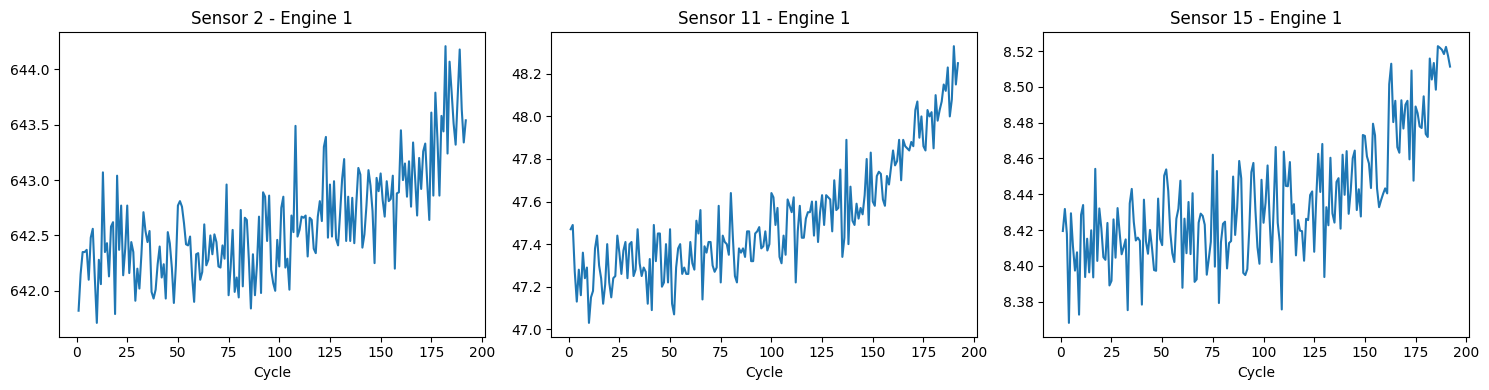

In [3]:
engine = train[train['unit'] == 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, ['s2', 's11', 's15']):
    ax.plot(engine['cycle'], engine[s])
    ax.set_title(f'Sensor {s[1:]} - Engine 1')
    ax.set_xlabel('Cycle')
plt.tight_layout()
plt.savefig('sensor_drift.png', dpi=150)
plt.show()

In [4]:
feature_cols = [c for c in cols if c not in ['unit', 'cycle']]
dropped = [c for c in feature_cols if train[c].std() < 0.01]
features = [c for c in feature_cols if c not in dropped]

print('Dropped:', dropped)
print('Using:', features)

Dropped: ['set1', 'set2', 'set3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
Using: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [5]:
from sklearn.ensemble import RandomForestRegressor

X_train = train[features]
y_train = train['RUL']

rf = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=12, n_jobs=-1, random_state=42)

In [6]:
from sklearn.metrics import mean_squared_error

test_last = test.groupby('unit').last().reset_index()
X_test = test_last[features]
y_true = rul_true['RUL'].clip(upper=125)

y_pred = rf.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f'Random forest RMSE: {rmse:.2f}')

Random forest RMSE: 17.22


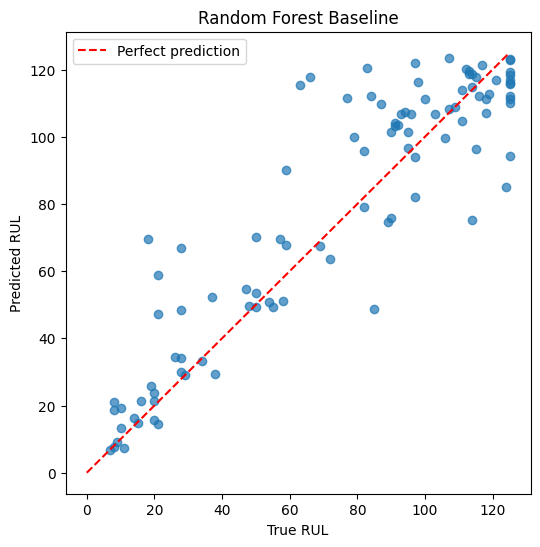

In [7]:
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.7)
plt.plot([0, 125], [0, 125], 'r--', label='Perfect prediction')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Random Forest Baseline')
plt.legend()
plt.savefig('baseline_pred_vs_true.png', dpi=150)
plt.show()